# Import packages & Load functions and data

In [1]:
import math
import pysam
import glob, os
import numpy as np
from collections import Counter
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt

import pyoncoprint

In [2]:
def process_vcf_oncoprint( vcf, columns=['SampleID', 'GeneName', 'CLNSIG', 'VarType', 'is_in_clinvar'] ):

    vcf_oncopring = vcf[columns].copy()

    vcf_oncopring['SampleID_GeneName'] = vcf_oncopring['SampleID'] + '_' + vcf_oncopring['GeneName']
    vcf_oncopring['benign'] = vcf_oncopring['CLNSIG'].str.contains("benign", case=False, na=False,)
    vcf_oncopring['pathogenic'] = vcf_oncopring['CLNSIG'].str.contains("pathogenic", case=False, na=False,)
    vcf_oncopring['conflicting'] = vcf_oncopring['CLNSIG'].str.contains("conflict", case=False, na=False,)
    vcf_oncopring = vcf_oncopring[(vcf_oncopring['pathogenic']==True)].copy()

    vcf_oncopring_collaped = list()
    for SampleID_GeneName, vcf_oncopring_e in vcf_oncopring.groupby('SampleID_GeneName'):
        SampleID, GeneName = SampleID_GeneName.split('_')

        VariantType = ",".join(
            f"{vartype}_x{len(group)}"
            for vartype, group in vcf_oncopring_e.groupby("VarType")
        )
        vcf_oncopring_collaped.append( [SampleID, GeneName, VariantType] )
    vcf_oncopring_collaped = pd.DataFrame(vcf_oncopring_collaped, columns=['Patient ID', 'gene', 'variant'])
    return vcf_oncopring_collaped

def collapse_variants(vcf, tool_hierarchy=['Sniffles2', 'ClairS_TO_SNV', 'ClairS_TO_indel', 'mutect2', 'bcftools',]):
    
    dict_tool_hierarchy = { elem : idx for idx, elem in enumerate(tool_hierarchy) }
    vcf['tool_hierarchy'] = vcf['tool'].map(dict_tool_hierarchy)

    vcf_collapsed = list()

    for Identifier_SampleID, edf in vcf.groupby('Identifier_SampleID', observed=True):

        if len(edf)>1:
            vcf_collapsed.append( edf.sort_values('tool_hierarchy', ascending=True).iloc[0] )
        else:
            vcf_collapsed.append( edf.iloc[0] )

    vcf_collapsed = pd.DataFrame(vcf_collapsed)
    vcf_collapsed.reset_index(inplace=True, drop=True)
    vcf_collapsed.drop( 'tool_hierarchy', inplace=True, axis=1 )
    print(f'{vcf.shape[0]} -> {vcf_collapsed.shape[0]}')
    return vcf_collapsed

def get_allele_counts(bamfile, chrom, pos, min_base_quality_e, min_mapping_quality):
    counts = Counter()

    for pileup_col in bamfile.pileup(
        chrom, pos-1, pos,          # narrow window = fast
        truncate=True,                 # only yield exactly [pos, pos+1)
        min_base_quality=min_base_quality_e,
        min_mapping_quality=min_mapping_quality,
        ignore_orphans=True,
        ignore_overlaps=True,          # avoid double-counting paired reads
    ):
        if pileup_col.reference_pos == pos-1:
            for pileup_read in pileup_col.pileups:
                if not pileup_read.is_del and not pileup_read.is_refskip:
                    base = pileup_read.alignment.query_sequence[pileup_read.query_position]
                    counts[base] += 1

    return dict(counts)

In [3]:
mutation_colors = {
    "missense_variant" : "lightcoral",
    "frameshift_variant" : "cornflowerblue",
    "stop_gained" : "dimgray",
    "splice_donor_variant" : "mediumpurple",
    "splice_region_variant" : "#0f9690",
    "synonymous_variant" : "#02b11a",
    "upstream_gene_variant" : "darkseagreen",
    "downstream_gene_variant" : "tan",
    "intron_variant" : "#000000",
    
    'disruptive_inframe_insertion' : '#800200',     # FLT3 ITD
    'conservative_inframe_insertion' : '#800200',   # FLT3 ITD
    'exon_loss_variant' : '#04008B', # IDH1 del

}

mutation_markers_baseline = {
    "missense_variant": dict(
        marker="fill",
        color=mutation_colors["missense_variant"],
        linewidth=0,
        zindex=1,
    ),
    "frameshift_variant": dict(
        marker="fill",
        color=mutation_colors["frameshift_variant"],
        linewidth=0,
        zindex=1,
    ),
    "stop_gained": dict(
        marker="fill",
        color=mutation_colors["stop_gained"],
        linewidth=0,
        zindex=1,
    ),
    "splice_donor_variant": dict(
        marker="fill",
        color=mutation_colors["splice_donor_variant"],
        linewidth=0,
        zindex=1,
    ),
    "splice_region_variant": dict(
        marker="fill",
        color=mutation_colors["splice_region_variant"],
        linewidth=0,
        zindex=1,
    ),
    "synonymous_variant": dict(
        marker="fill",
        color=mutation_colors["synonymous_variant"],
        linewidth=0,
        zindex=1,
    ),
    "upstream_gene_variant": dict(
        marker="fill",
        color=mutation_colors["upstream_gene_variant"],
        linewidth=0,
        zindex=1,
    ),
    "downstream_gene_variant": dict(
        marker="fill",
        color=mutation_colors["downstream_gene_variant"],
        linewidth=0,
        zindex=1,
    ),
    "intron_variant": dict(
        marker="fill",
        color=mutation_colors["intron_variant"],
        linewidth=0,
        zindex=1,
    ),

    "disruptive_inframe_insertion": dict(
        marker="fill",
        color=mutation_colors["disruptive_inframe_insertion"],
        linewidth=0,
        zindex=1,
    ),
    "conservative_inframe_insertion": dict(
        marker="fill",
        color=mutation_colors["conservative_inframe_insertion"],
        linewidth=0,
        zindex=1,
    ),
    "exon_loss_variant": dict(
        marker="fill",
        color=mutation_colors["exon_loss_variant"],
        linewidth=0,
        zindex=1,
    ),
}

dict_VarType_to_color = {
    'downstream_gene_variant' : 'silver',
    'upstream_gene_variant' : 'silver',
    '5_prime_UTR_variant' : 'silver',
    '3_prime_UTR_variant' : 'silver',
    'missense_variant' : 'lightcoral',
    'synonymous_variant' : 'silver',
    'splice_region_variant' : '#0f9690',
    'frameshift_variant' : 'cornflowerblue',
    'exon_loss_variant' : 'firebrick',
    'gene_fusion' : 'indigo',
}

## Load VCFs

In [4]:
DIR_data = f'/home/18parkky/data/aml/paper'

# Load VCFs
PATH_NGS_total_variants_clnsig_updated = f'{DIR_data}/final_vcfs/AML_NGS_annotated_variants_total.clnsig_updated.tsv.gz'
PATH_ONT_total_variants_clnsig_updated = f'{DIR_data}/final_vcfs/AML_ONT_annotated_variants_total.clnsig_updated.tsv.gz'

NGS_variants = pd.read_csv(PATH_NGS_total_variants_clnsig_updated, sep='\t')
ONT_variants = pd.read_csv(PATH_ONT_total_variants_clnsig_updated, sep='\t')

# Replace missing CLNSIG and AaChange values with string values
NGS_variants['CLNSIG'] = NGS_variants['CLNSIG'].fillna('NotAvailable')
ONT_variants['CLNSIG'] = ONT_variants['CLNSIG'].fillna('NotAvailable')

NGS_variants['AaChange'] = NGS_variants['AaChange'].fillna('NotAvailable')
ONT_variants['AaChange'] = ONT_variants['AaChange'].fillna('NotAvailable')

NGS_variants['VarType'] = NGS_variants['VarType'].fillna('NotAvailable')
ONT_variants['VarType'] = ONT_variants['VarType'].fillna('NotAvailable')

NGS_variants = NGS_variants[(NGS_variants['SampleID']!='barcode53')].copy() 
ONT_variants = ONT_variants[(ONT_variants['SampleID']!='barcode53')].copy() 

NGS_variants['REF_length'] = NGS_variants['REF'].apply( len )
NGS_variants['ALT_length'] = NGS_variants['ALT'].apply( len )

ONT_variants['REF_length'] = ONT_variants['REF'].apply( len )
ONT_variants['ALT_length'] = ONT_variants['ALT'].apply( len )

# The following entries were manually checked using Clinvar database 
# to see if they are annotated as pathogenic or likely pathogenic (2026.06.27)

dict_Identifier_to_CLNSIG_m = {
    'chr5:171410539:C:CTCTG' : 'Pathogenic',
    'chr19:33301478:T:TCTG' : 'NotAvailable',
    'chr7:50400546:CAT:C' : 'Likely pathogenic',
    'chr11:118473778:TAG:T' : 'Pathogenic',
    'chr20:32434599:TCACCACTGCCATAGAGAGGCGGC:T' : 'Pathogenic/Likely pathogenic',
    'chr13:28018505:C:A,G' : 'Pathogenic',
    'chr17:7676152:CG:C' : 'Pathogenic',
}

NGS_variants['CLNSIG'] = [ dict_Identifier_to_CLNSIG_m.get(tup.Identifier, tup.CLNSIG) for tup in NGS_variants.itertuples() ]
ONT_variants['CLNSIG'] = [ dict_Identifier_to_CLNSIG_m.get(tup.Identifier, tup.CLNSIG) for tup in ONT_variants.itertuples() ]

/tmp/ipykernel_2557821/2926853486.py:8: DtypeWarning: Columns (17) have mixed types. Specify dtype option on import or set low_memory=False.
  ONT_variants = pd.read_csv(PATH_ONT_total_variants_clnsig_updated, sep='\t')


## Clinvar variants

In [5]:
NGS_variants_clinvar = NGS_variants[~(NGS_variants['CLNSIG'].isin( ['Not provided', 'NotAvailable'] ))].copy()
ONT_variants_clinvar = ONT_variants[~(ONT_variants['CLNSIG'].isin( ['Not provided', 'NotAvailable'] ))].copy()

NGS_variants_clinvar['ALT'] = NGS_variants_clinvar['ALT'].replace({'A,G' : 'G'}, )

NGS_variants_clinvar['Identifier'] = [ f'{list(tup)[1]}:{tup.POS}:{tup.REF}:{tup.ALT}' for tup in NGS_variants_clinvar.itertuples() ]
ONT_variants_clinvar['Identifier'] = [ f'{list(tup)[1]}:{tup.POS}:{tup.REF}:{tup.ALT}' for tup in ONT_variants_clinvar.itertuples() ]

NGS_variants_clinvar['Identifier_SampleID'] = [ f'{tup.SampleID}_{tup.Identifier}' for tup in NGS_variants_clinvar.itertuples() ]
ONT_variants_clinvar['Identifier_SampleID'] = [ f'{tup.SampleID}_{tup.Identifier}' for tup in ONT_variants_clinvar.itertuples() ]

ONT_variants_clinvar_s = ONT_variants_clinvar[(ONT_variants_clinvar['config']=='sup')].copy()

NGS_variants_clinvar    = collapse_variants(NGS_variants_clinvar,)
ONT_variants_clinvar_s  = collapse_variants(ONT_variants_clinvar_s,)

NGS_variants_clinvar["is_pathogenic"] = (
    NGS_variants_clinvar["CLNSIG"]
    .str.contains("pathogenic", case=False, na=False)
)

ONT_variants_clinvar_s["is_pathogenic"] = (
    ONT_variants_clinvar_s["CLNSIG"]
    .str.contains("pathogenic", case=False, na=False)
)

1002 -> 536
2837 -> 2836


## Non-clinvar variants

In [6]:
NGS_variants_n_clinvar      = NGS_variants[(NGS_variants['CLNSIG'].isin( ['NotAvailable'] ))].copy()
ONT_variants_n_clinvar_s    = ONT_variants[(ONT_variants['CLNSIG'].isin( ['NotAvailable'] ))].copy()

NGS_variants_n_clinvar["VarImpact_isHIGH"] = (
    NGS_variants_n_clinvar["VarImpact"]
    .str.contains("high", case=False, na=False)
)
ONT_variants_n_clinvar_s["VarImpact_isHIGH"] = (
    ONT_variants_n_clinvar_s["VarImpact"]
    .str.contains("high", case=False, na=False)
)

NGS_variants_n_clinvar = NGS_variants_n_clinvar[(NGS_variants_n_clinvar['VarImpact_isHIGH']==True) & 
                                                (NGS_variants_n_clinvar['VarType']!='intron_variant') & 
                                                (NGS_variants_n_clinvar['AF']>=0.05) & 
                                                (NGS_variants_n_clinvar['DP']>=50)].copy()
ONT_variants_n_clinvar_s = ONT_variants_n_clinvar_s[(ONT_variants_n_clinvar_s['VarImpact_isHIGH']==True) & 
                                        (ONT_variants_n_clinvar_s['VarType']!='intron_variant') & 
                                        (ONT_variants_n_clinvar_s['AF']>=0.05) & 
                                        (ONT_variants_n_clinvar_s['DP']>=50) &
                                        (ONT_variants_n_clinvar_s['config']=='sup')].copy()

NGS_variants_n_clinvar['Identifier_SampleID'] = [ f'{tup.SampleID}_{tup.Identifier}' for tup in NGS_variants_n_clinvar.itertuples() ]
ONT_variants_n_clinvar_s['Identifier_SampleID'] = [ f'{tup.SampleID}_{tup.Identifier}' for tup in ONT_variants_n_clinvar_s.itertuples() ]

NGS_variants_n_clinvar    = collapse_variants(NGS_variants_n_clinvar,)
ONT_variants_n_clinvar_s  = collapse_variants(ONT_variants_n_clinvar_s,)

56 -> 31
34 -> 34


In [8]:
ONT_relevant_variants = pd.concat([ONT_variants_clinvar_s[(ONT_variants_clinvar_s['is_pathogenic']==True)], ONT_variants_n_clinvar_s])
ONT_relevant_variants.to_csv(f'{DIR_data}/final_vcfs/AML_ONT_annotated_variants_total.clnsig_updated.deleterious.tsv.gz', sep='\t', index=False,)

## SV

In [7]:
# Select SVs with potential functional impacts
potential_deleterious_VarTypes = [
    'bidirectional_gene_fusion',
    'chromosome_number_variation',
    'conservative_inframe_deletion',
    'conservative_inframe_insertion',
    'disruptive_inframe_deletion',
    'disruptive_inframe_insertion',
    'duplication',
    'exon_loss_variant',
    'feature_ablation',
    'feature_fusion',
    'frameshift_variant',
    'gene_fusion',
    'inversion',
    'missense_variant',
    'splice_acceptor_variant',
    'splice_donor_variant',
    'splice_region_variant',
    'start_lost',
    'stop_gained',
    'stop_lost',
    'transcript_ablation',
]

SV_length = 30
supporting_reads = 10

ONT_variants_SV = ONT_variants[((ONT_variants['REF_length']>=SV_length) | (ONT_variants['ALT_length']>=SV_length) & (ONT_variants['DP']>=supporting_reads)) & (ONT_variants['FILTER']=='PASS')].copy()
ONT_variants_SV = ONT_variants_SV[~(ONT_variants_SV['GeneName'].isna())]

ONT_variants_SV_s = ONT_variants_SV[(ONT_variants_SV['config']=='sup')].copy()
ONT_variants_SV_s_VarTypeFilt = ONT_variants_SV_s[(ONT_variants_SV_s['VarType']!='intron_variant')].copy()

ONT_variants_SV_del = ONT_variants_SV_s[(ONT_variants_SV_s['VarType'].isin( potential_deleterious_VarTypes ) & 
                                        (ONT_variants_SV_s['FILTER']=='PASS') & 
                                        (ONT_variants_SV_s['GeneName']!=''))].copy()
                                        
ONT_variants_SV_del = ONT_variants_SV_del[(ONT_variants_SV_del['DP']>=10)].copy()
ONT_variants_SV_del['ALT_length'] = ONT_variants_SV_del['ALT_length'] - 1

ONT_variants_SV_del.shape[0]

12

# Figure 3a - Oncoprint

In [8]:
ONT_variants_clinvar_s['VarClass'] = 'Small variant'
ONT_variants_n_clinvar_s['VarClass'] = 'Small variant (not in clinvar)'
ONT_variants_SV_del['VarClass'] = 'Structural variant'

oncoprint_relevant_columns = ['SampleID', 'FILTER', 'GeneName', 'CLNSIG', 'VarType', 'VarClass',]

ONT_variants_s_total_SV_included = pd.concat( [ ONT_variants_clinvar_s[oncoprint_relevant_columns], 
                                                ONT_variants_n_clinvar_s[oncoprint_relevant_columns], 
                                                ONT_variants_SV_del[oncoprint_relevant_columns]] )

ONT_variants_s_total_SV_included[(ONT_variants_s_total_SV_included['VarClass']=='Structural variant')]
ONT_variants_s_total_SV_included['SampleID_GeneName'] = ONT_variants_s_total_SV_included['SampleID'] + '_' + ONT_variants_s_total_SV_included['GeneName']

ONT_variants_s_total_SV_included['pathogenic'] = ONT_variants_s_total_SV_included['CLNSIG'].str.contains("pathogenic", case=False, na=False,)
ONT_variants_s_total_SV_included = ONT_variants_s_total_SV_included[((ONT_variants_s_total_SV_included['FILTER']=='PASS') & (ONT_variants_s_total_SV_included['pathogenic']==True) & (ONT_variants_s_total_SV_included['VarClass']=='Small variant')) | 
                                                                    ((ONT_variants_s_total_SV_included['FILTER']=='PASS') & (ONT_variants_s_total_SV_included['VarClass']=='Small variant (not in clinvar)')) | 
                                                                    (ONT_variants_s_total_SV_included['VarClass']=='Structural variant')].copy()

ONT_variants_s_total_SV_included_collapsed = list()
for SampleID_GeneName, ONT_variants_s_total_SV_included_e in ONT_variants_s_total_SV_included.groupby('SampleID_GeneName'):
    SampleID, GeneName = SampleID_GeneName.split('_')
    VariantType = ",".join(
        f"{vartype}_x{len(group)}"
        for vartype, group in ONT_variants_s_total_SV_included_e.groupby("VarType")
    )
    ONT_variants_s_total_SV_included_collapsed.append( [SampleID, GeneName, VariantType] )
ONT_variants_s_total_SV_included_collapsed = pd.DataFrame(ONT_variants_s_total_SV_included_collapsed, columns=['Patient ID', 'gene', 'variant'])
ONT_variants_s_total_SV_included_collapsed['variant_collapsed'] = [ variant.split('_x')[0] for variant in ONT_variants_s_total_SV_included_collapsed['variant'] ] # ?!

dict_temp = { #! In Powerpoint, manually change the Oncoplot to properly show multiple variants on the same sample!
    'frameshift_variant&stop_gained' : 'frameshift_variant',
    'missense_variant&splice_region_variant' : 'splice_region_variant',
    'missense_variant,downstream_gene_variant,upstream_gene_variant' : 'missense_variant',
    'splice_donor_variant&intron_variant' : 'intron_variant',
    'downstream_gene_variant,upstream_gene_variant,missense_variant' : 'missense_variant',
    'upstream_gene_variant,downstream_gene_variant,missense_variant' : 'missense_variant',
    'splice_donor_variant&5_prime_UTR_variant&intron_variant,splice_region_variant,non_coding_transcript_variant' : 'splice_region_variant',
    'splice_donor_variant&intron_variant' : 'splice_donor_variant',
    'downstream_gene_variant,frameshift_variant' : 'frameshift_variant'


    # 'disruptive_inframe_insertion' : 'missense_variant',
    # 'exon_loss_variant' : 'missense_variant',
    # 'conservative_inframe_insertion' : 'missense_variant',
}
ONT_variants_s_total_SV_included_collapsed['variant_oncoprint'] = [ dict_temp.get(variant, variant) for variant in ONT_variants_s_total_SV_included_collapsed['variant_collapsed'] ]

ONT_variants_s_total_SV_included_collapsed_pivot = ONT_variants_s_total_SV_included_collapsed.pivot(index='gene', columns='Patient ID', values='variant_oncoprint')
ONT_variants_s_total_SV_included_collapsed_pivot.fillna('', inplace=True)

ONT_op = pyoncoprint.OncoPrint(ONT_variants_s_total_SV_included_collapsed_pivot)

NGS_variants = NGS_variants[(NGS_variants['SampleID']!='barcode53')].copy() 
ONT_variants = ONT_variants[(ONT_variants['SampleID']!='barcode53')].copy() 

In [9]:
plt.rcParams['figure.dpi'] = 500
fig, axes = ONT_op.oncoprint(mutation_markers_baseline,
                         figsize=[32, 18], 
                         gap=[0.12, 0.12],                     # gap between cells (ratio)
                         topplot=True, rightplot=True, legend=True)
# return values: figure, (oncoprint_axis, oncoprint_dual_axis, axis_top_barplot, axis_right_barplot, axis_legend)
fig.patch.set_facecolor('white')
plt.show()

# Figure 3b - Variant distribution

In [12]:
dict_VarType_count = dict()
for VarType_entry in ONT_variants['VarType']:
    for VarType in VarType_entry.split(','):
        for VarType_ in VarType.split('&'):
            try: dict_VarType_count[VarType_] += 1
            except KeyError: dict_VarType_count[VarType] = 1

ONT_VarType_distribution = pd.DataFrame.from_dict(dict_VarType_count, orient='index')
ONT_VarType_distribution.reset_index(inplace=True)
ONT_VarType_distribution.columns = ['VarType', 'ONT_count']

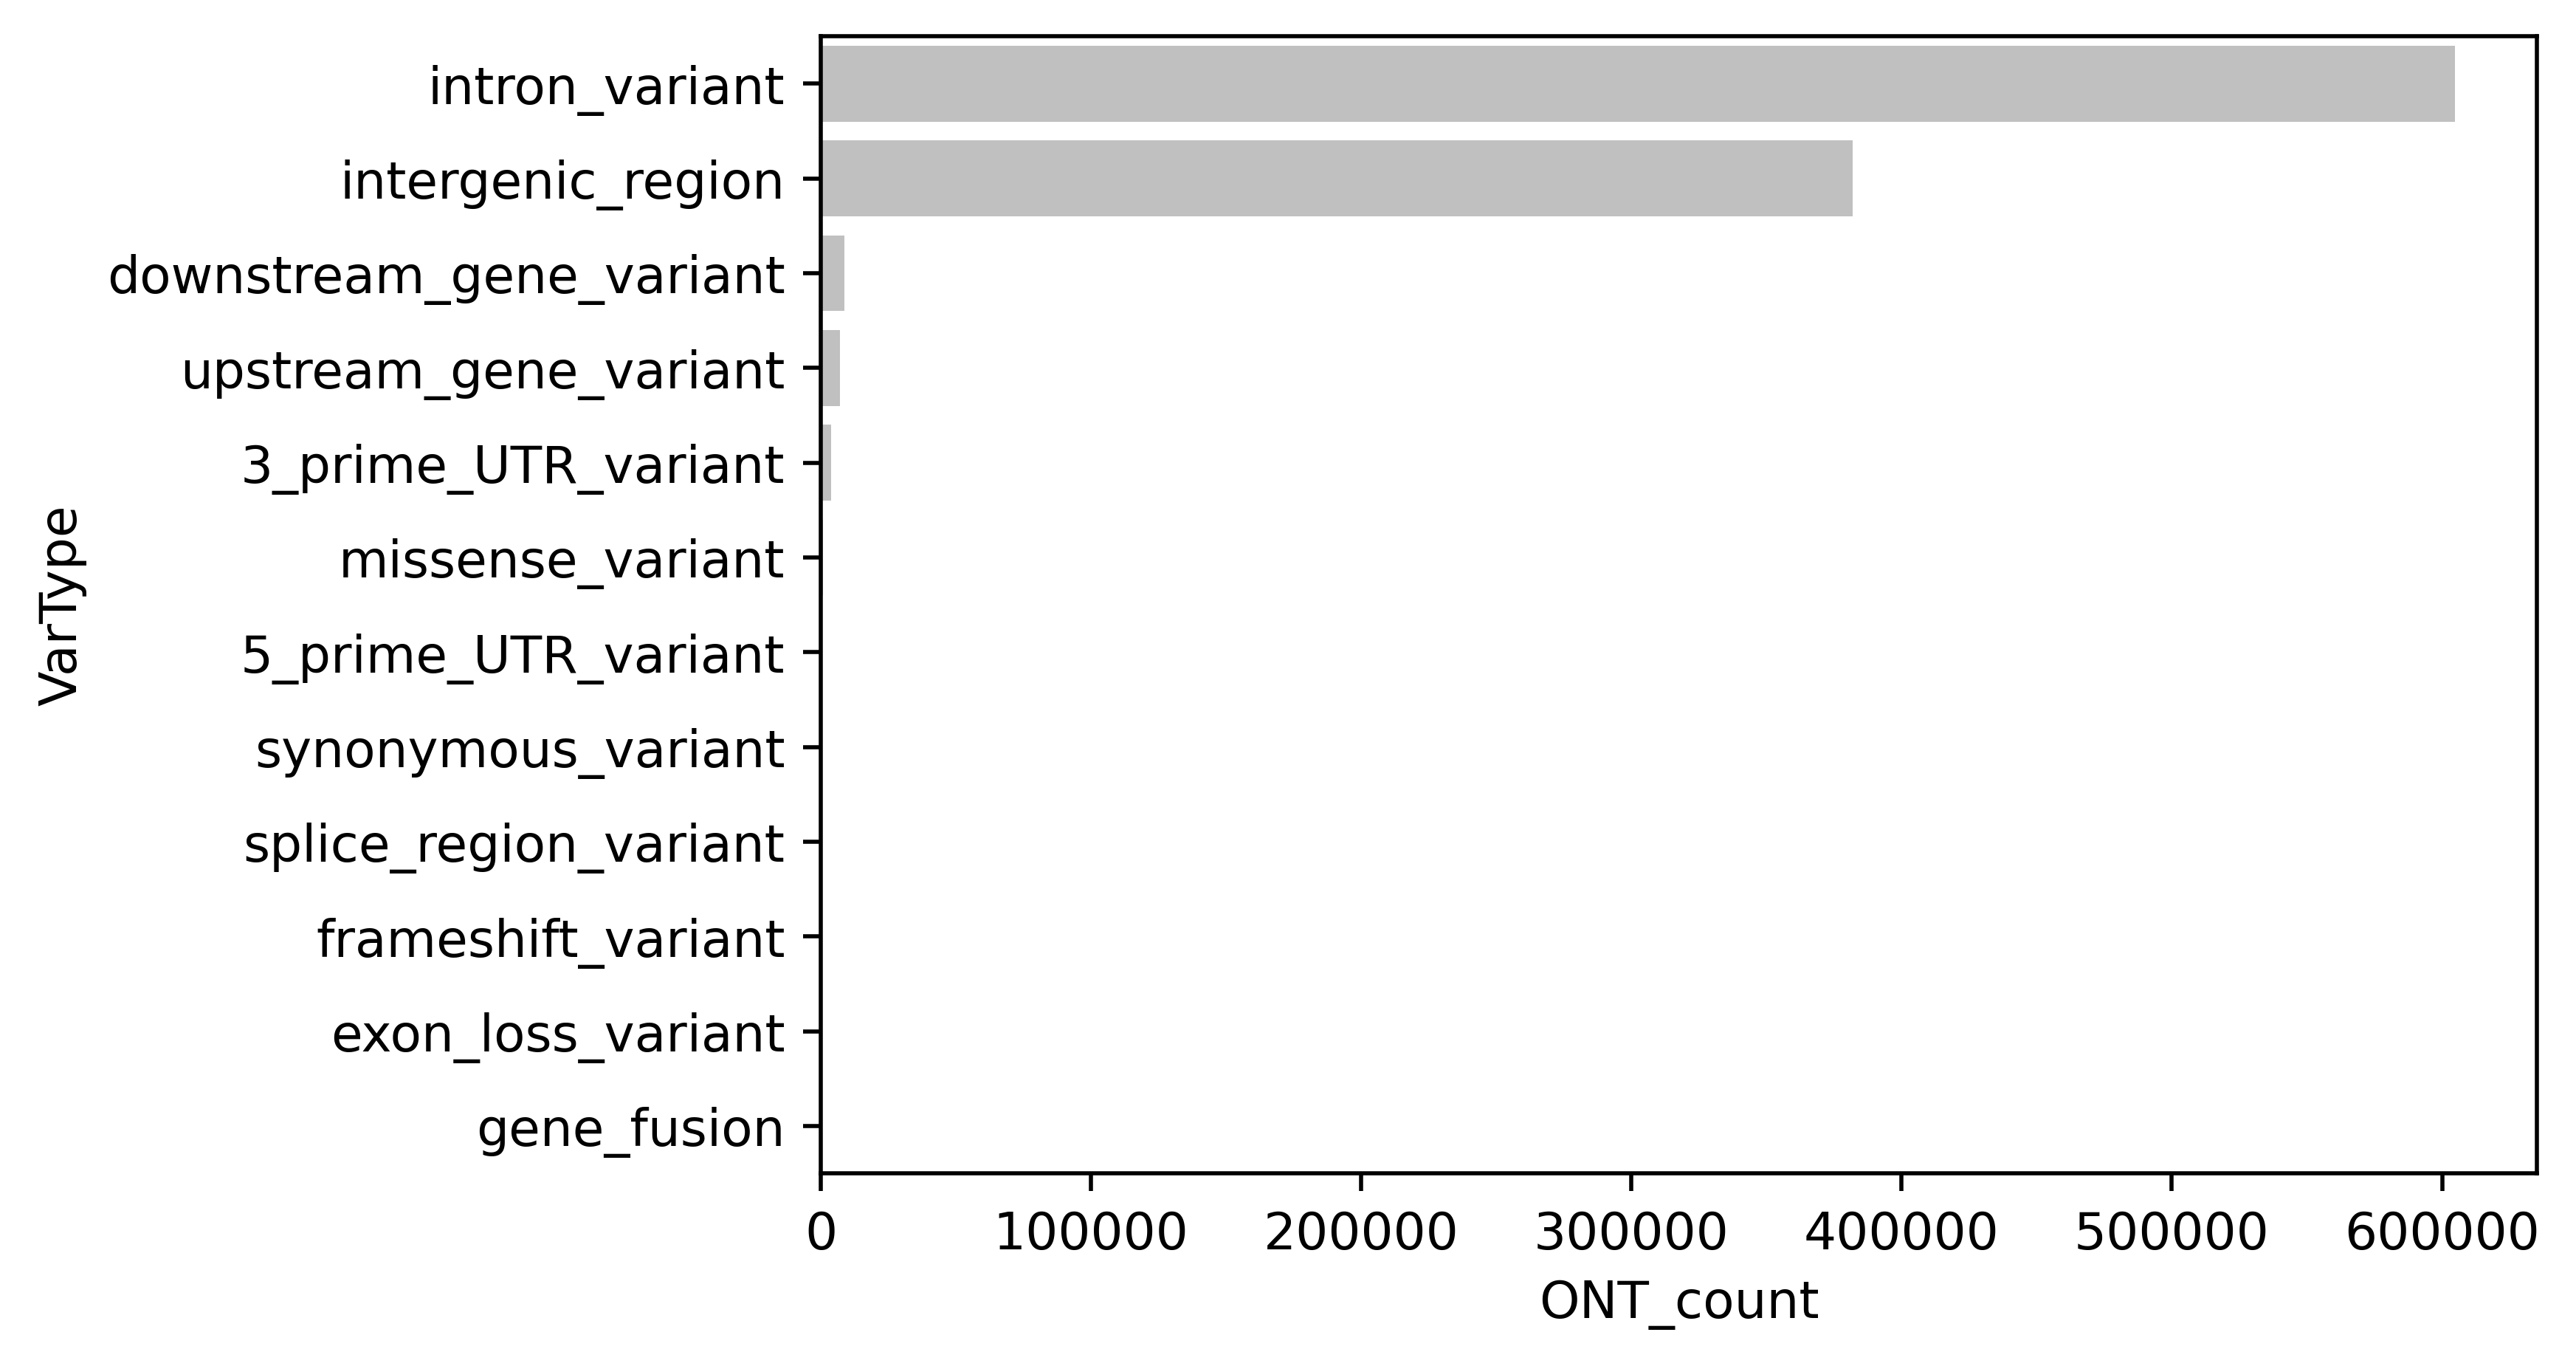

In [14]:
plt.figure(figsize=(6, 4), dpi=500)
ax = sns.barplot(data=ONT_VarType_distribution[(ONT_VarType_distribution['VarType']!='NotAvailable')].sort_values('ONT_count', ascending=False,).head(12), 
                 x='ONT_count', y='VarType', color='silver')
# ax.set_xticklabels([]);
# ax.set_yticklabels([]);
# ax.set_xlabel('');
# ax.set_ylabel('');

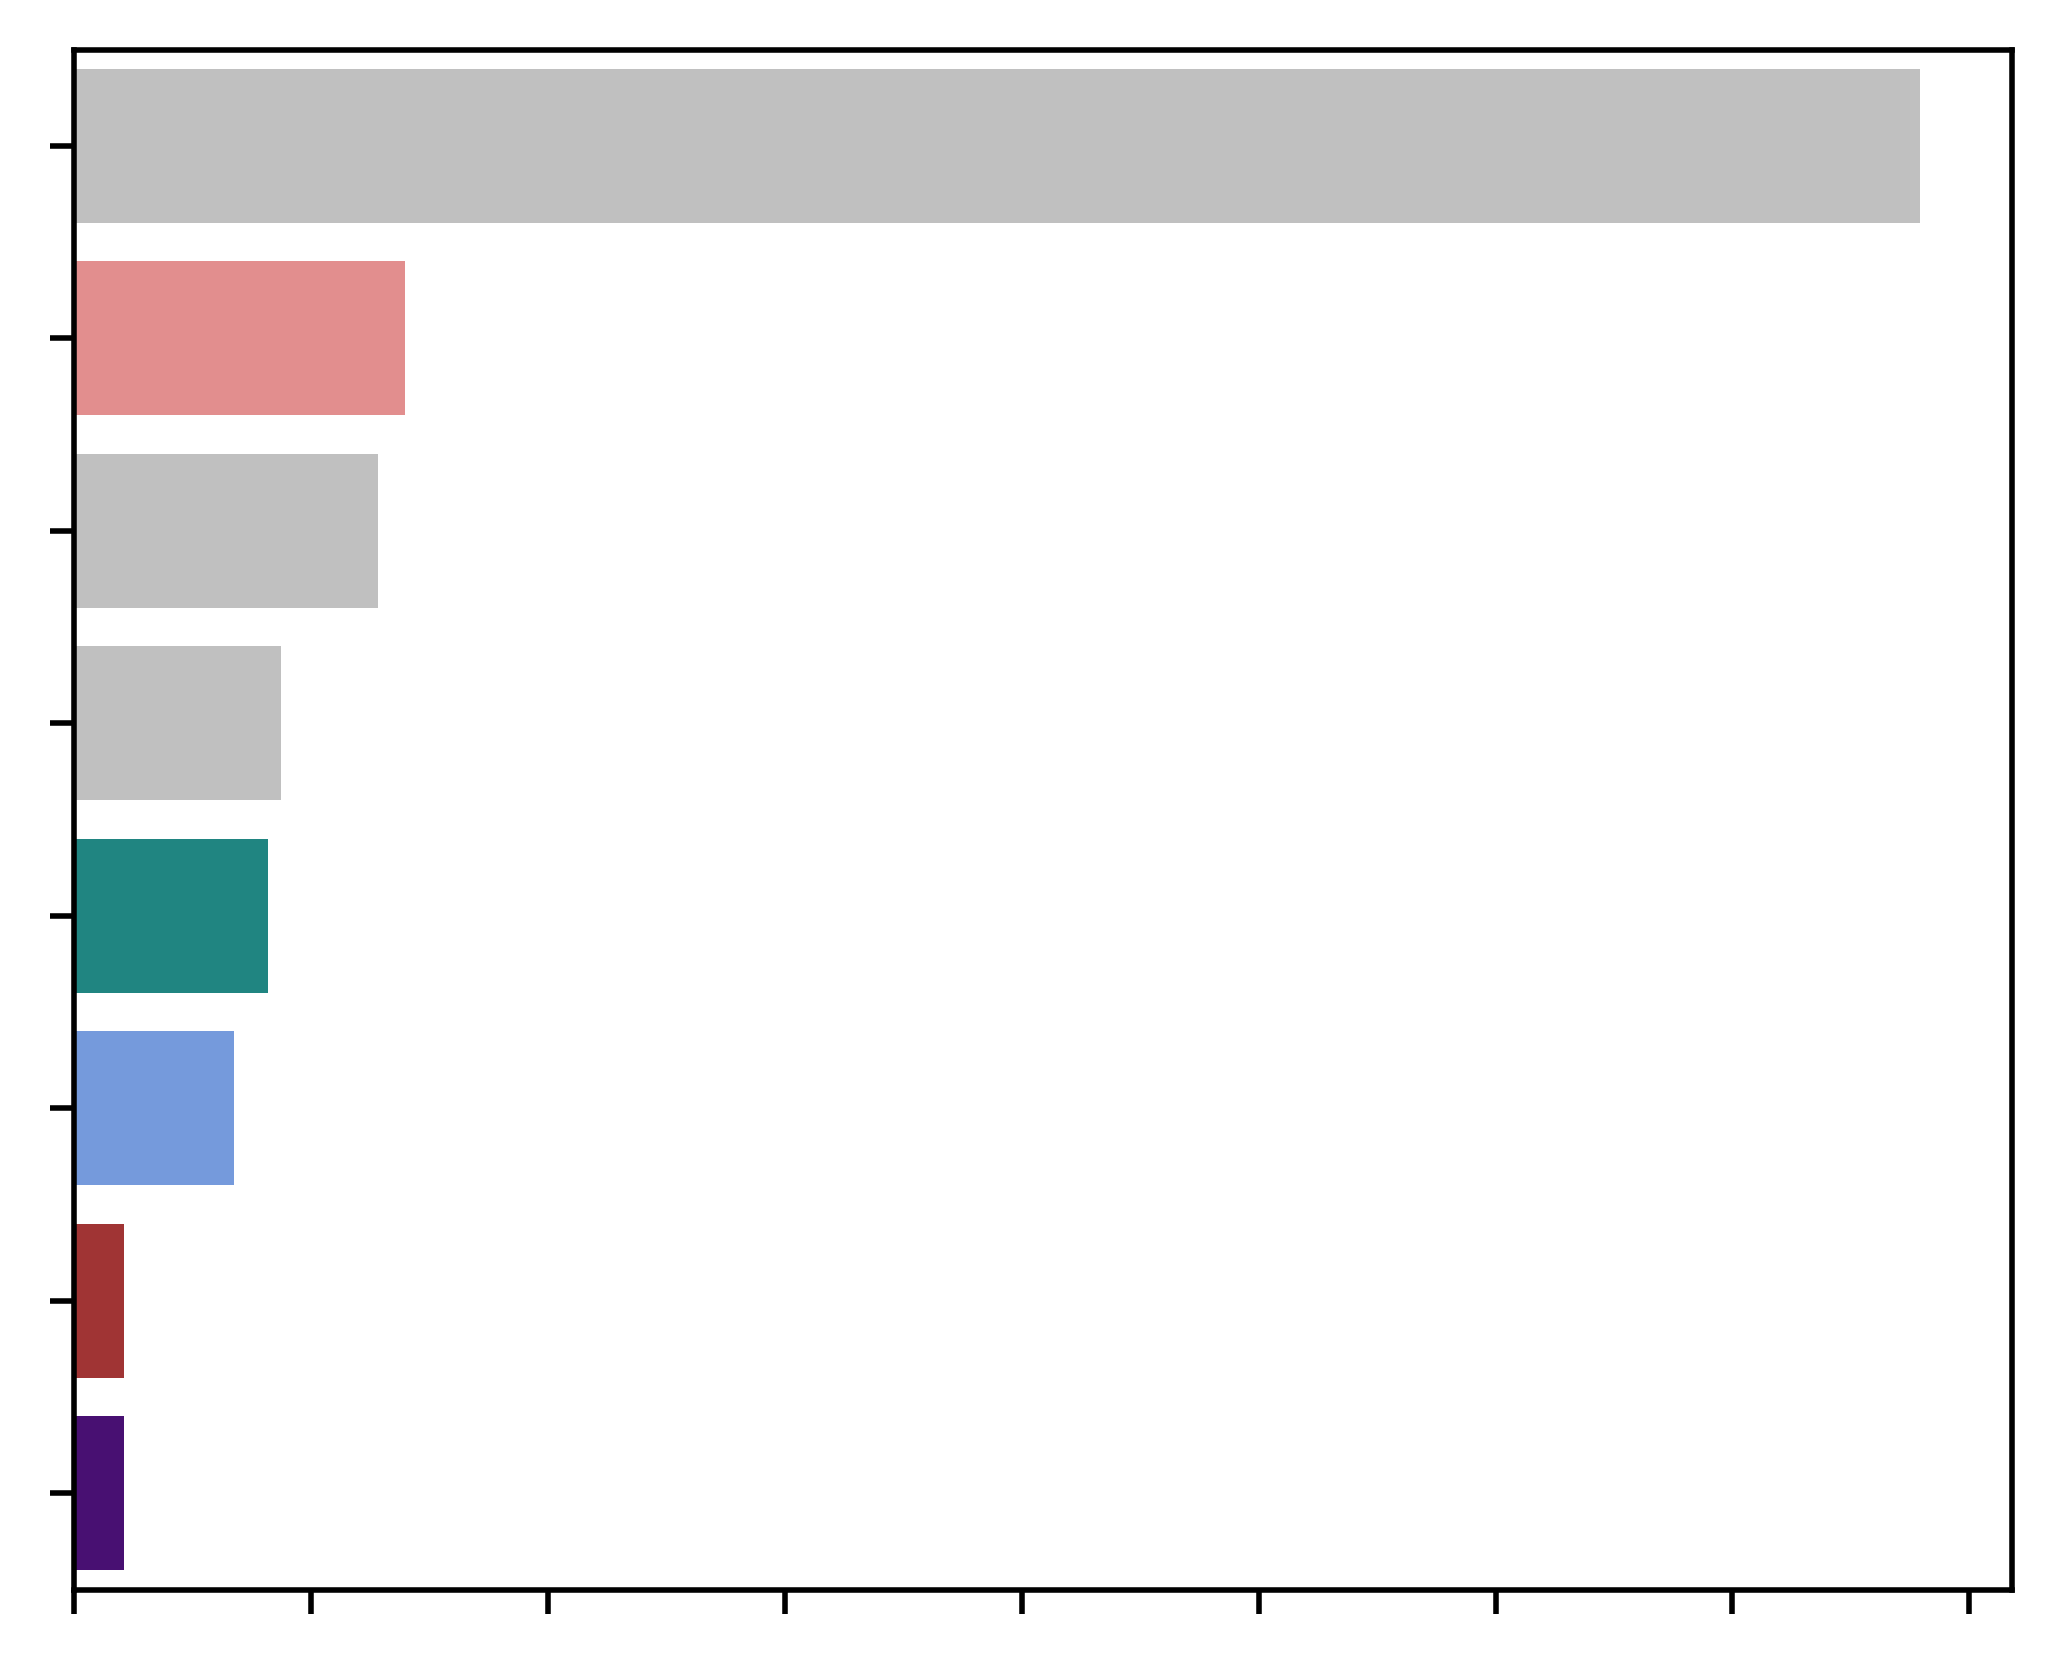

In [17]:

plt.figure(figsize=(5, 4), dpi=500)
ax = sns.barplot(data=ONT_VarType_distribution[(ONT_VarType_distribution['VarType']!='NotAvailable')].sort_values('ONT_count', ascending=False,).head(12).iloc[4:], 
                 x='ONT_count', y='VarType', color='silver',
                 hue='VarType', palette=dict_VarType_to_color,
                 )
ax.set_xticklabels([]);
ax.set_yticklabels([]);
ax.set_xlabel('');
ax.set_ylabel('');

# Figure 3c - Venn diagram (NGS vs. ONT)

In [98]:
set_ONT_variants_s  = set(ONT_variants_clinvar_s['Identifier_SampleID'])
set_NGS_variants    = set(NGS_variants_clinvar['Identifier_SampleID'])

set_ONT_patho_variants_s  = set(ONT_variants_clinvar_s[(ONT_variants_clinvar_s['is_pathogenic']==True)]['Identifier_SampleID'])
set_NGS_patho_variants    = set(NGS_variants_clinvar[(NGS_variants_clinvar['is_pathogenic']==True)]['Identifier_SampleID'])

set_ONT_variants_s_2  = set(ONT_variants_n_clinvar_s['Identifier_SampleID'])
set_NGS_variants_2    = set(NGS_variants_n_clinvar['Identifier_SampleID']) 

print(f'All ClinVar variants:')
print(f'\t{len(set_ONT_variants_s)}, {len(set_NGS_variants)}, {len(set_ONT_variants_s.intersection(set_NGS_variants))}')

print(f'Pathogenic or Likely_pathogenic variants:')
print(f'\t{len(set_ONT_patho_variants_s)}, {len(set_NGS_patho_variants)}, {len(set_ONT_patho_variants_s.intersection(set_NGS_patho_variants))}')

print(f'Deleterious non-clinvar variants:')
print(f'\t{len(set_ONT_variants_s_2)}, {len(set_NGS_variants_2)}, {len(set_ONT_variants_s_2.intersection(set_NGS_variants_2))}')


All ClinVar variants:
	2836, 536, 475
Pathogenic or Likely_pathogenic variants:
	58, 60, 54
Deleterious non-clinvar variants:
	34, 31, 26


# Figure 3d - Variants missed by ONT

5.6000000000000005
50.080000000000005


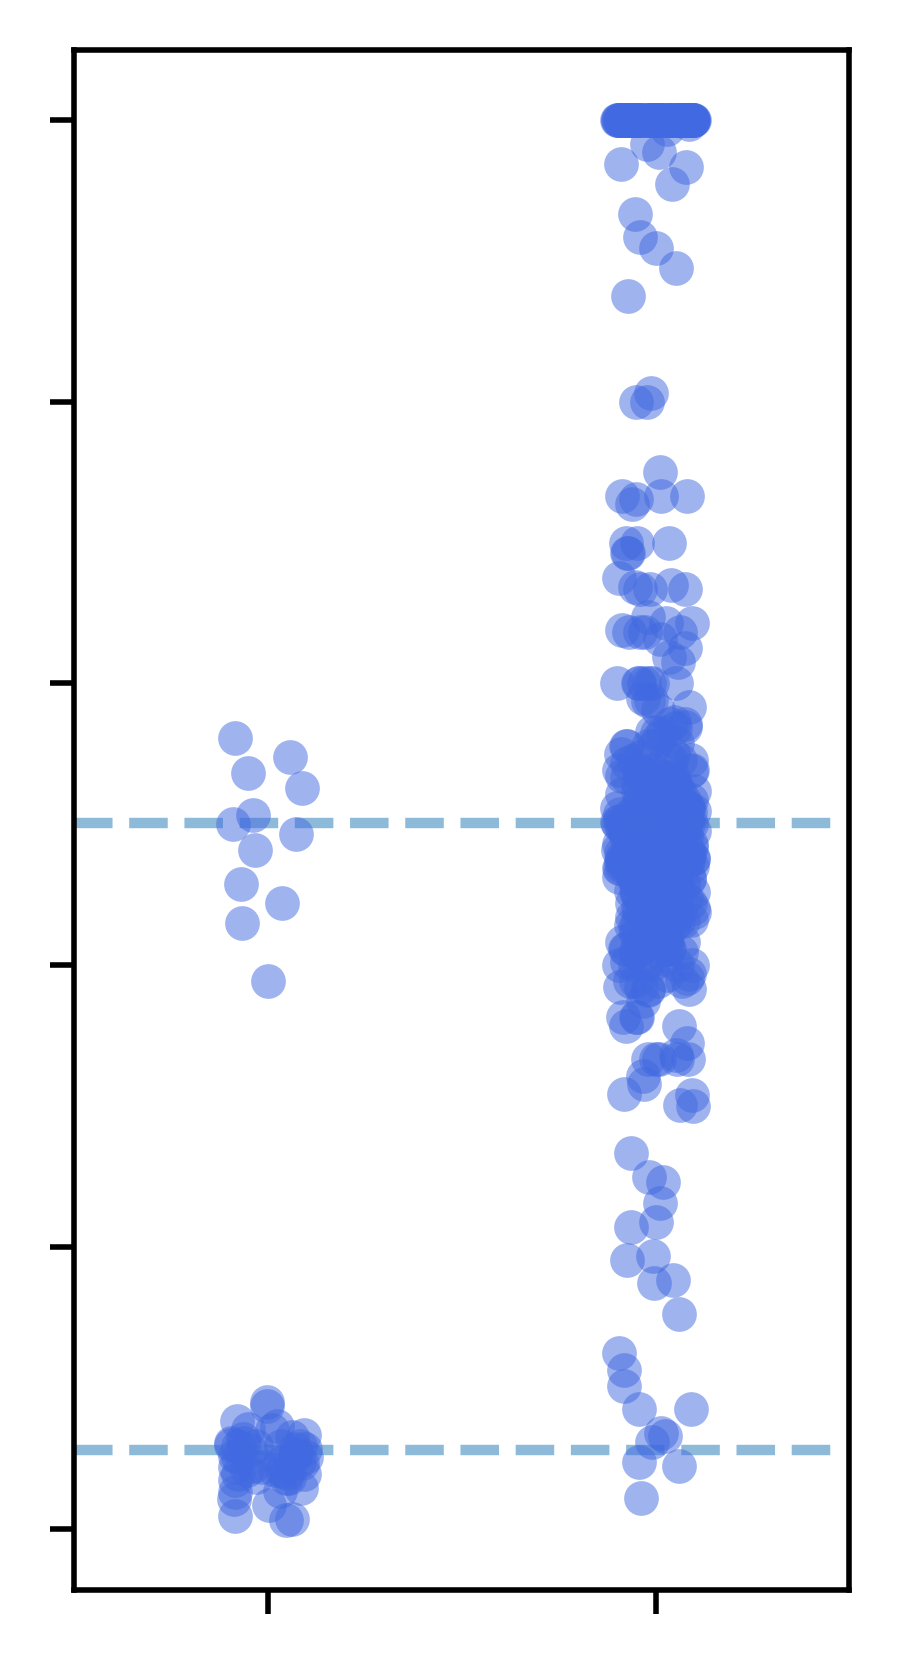

In [104]:
intersecting_clinvar_variants = set_ONT_variants_s.intersection(set_NGS_variants)

NGS_variants_clinvar_copy = NGS_variants_clinvar.copy()
ONT_variants_clinvar_copy = ONT_variants_clinvar_s.copy()

NGS_variants_clinvar_copy['intersecting'] = [ bool(Identifier_SampleID in intersecting_clinvar_variants) for Identifier_SampleID in NGS_variants_clinvar_copy['Identifier_SampleID'] ]
ONT_variants_clinvar_copy['intersecting'] = [ bool(Identifier_SampleID in intersecting_clinvar_variants) for Identifier_SampleID in ONT_variants_clinvar_copy['Identifier_SampleID'] ]

plt.figure(figsize=(2, 4), dpi=500);
ax = sns.stripplot(data=NGS_variants_clinvar_copy, x='intersecting', y='AF', alpha=0.5, color='royalblue')
for intersecting, edf in NGS_variants_clinvar_copy.groupby('intersecting'):
    print(100*np.median(edf['AF']))
    ax.axhline( np.median(edf['AF']), linestyle='--', alpha=0.5,  )

ax.set_xlabel('');
ax.set_ylabel('');
ax.set_xticklabels([]);
ax.set_yticklabels([]);

plt.show()

## Variants with VAF ~50% but still missed by ONT → repeat region

In [105]:
NGS_variants_clinvar_copy[(NGS_variants_clinvar_copy['intersecting']==False) & (NGS_variants_clinvar_copy['AF']>=0.2)]

,#CHROM,POS,ID,REF,ALT,QUAL,FILTER,INFO,FORMAT,VALUES,...,AaChange,LOF,DP_str,AF_str,CLNSIG_depr,REF_length,ALT_length,Identifier_SampleID,is_pathogenic,intersecting
12,chr17,7676341,rs139100308,T,C,0.0,LowQual;NonSomatic,FAU=0;FCU=19;FGU=0;FTU=5;RAU=0;RCU=8;RGU=0;RTU...,GT:GQ:DP:AF:AD:AU:CU:GU:TU,"0/1:1:59:0.4576:32,27:0:27:0:32",...,NotAvailable,NotAvailable,59,0.4576,Likely benign,1,1,barcode10_chr17:7676341:T:C,False,False
22,chr17,7676341,rs139100308,T,C,0.0,LowQual;NonSomatic,FAU=0;FCU=39;FGU=0;FTU=10;RAU=0;RCU=12;RGU=0;R...,GT:GQ:DP:AF:AD:AU:CU:GU:TU,"0/1:4:97:0.5258:46,51:0:51:0:46",...,NotAvailable,NotAvailable,97,0.5258,Likely benign,1,1,barcode11_chr17:7676341:T:C,False,False
31,chr17,7676341,rs139100308,T,C,0.0,LowQual;NonSomatic,FAU=0;FCU=31;FGU=0;FTU=8;RAU=0;RCU=9;RGU=0;RTU...,GT:GQ:DP:AF:AD:AU:CU:GU:TU,"0/1:1:73:0.5479:33,40:0:40:0:33",...,NotAvailable,NotAvailable,73,0.5479,Likely benign,1,1,barcode12_chr17:7676341:T:C,False,False
58,chr17,7676341,rs139100308,T,C,0.0,LowQual;NonSomatic,FAU=0;FCU=24;FGU=0;FTU=9;RAU=0;RCU=13;RGU=0;RT...,GT:GQ:DP:AF:AD:AU:CU:GU:TU,"0/1:4:75:0.4933:38,37:0:37:0:38",...,NotAvailable,NotAvailable,75,0.4933,Likely benign,1,1,barcode15_chr17:7676341:T:C,False,False
62,chr17,7676341,rs139100308,T,C,0.0,LowQual;NonSomatic,FAU=0;FCU=27;FGU=0;FTU=9;RAU=0;RCU=13;RGU=0;RT...,GT:GQ:DP:AF:AD:AU:CU:GU:TU,"0/1:1:93:0.4301:53,40:0:40:0:53",...,NotAvailable,NotAvailable,93,0.4301,Likely benign,1,1,barcode16_chr17:7676341:T:C,False,False
262,chr17,7676367,rs200053580,A,G,22.1495,NonSomatic,FAU=32;FCU=0;FGU=27;FTU=0;RAU=18;RCU=0;RGU=13;...,GT:GQ:DP:AF:AD:AU:CU:GU:TU,"0/1:22:90:0.4444:50,40:50:0:40:0",...,NotAvailable,NotAvailable,90,0.4444,Likely benign,1,1,barcode43_chr17:7676367:A:G,False,False
287,chr17,7676341,rs139100308,T,C,0.0,LowQual;NonSomatic,FAU=0;FCU=28;FGU=0;FTU=10;RAU=0;RCU=10;RGU=0;R...,GT:GQ:DP:AF:AD:AU:CU:GU:TU,"0/1:6:75:0.5067:37,38:0:38:0:37",...,NotAvailable,NotAvailable,75,0.5067,Likely benign,1,1,barcode45_chr17:7676341:T:C,False,False
299,chr17,7676341,rs139100308,T,C,0.0,LowQual;NonSomatic,FAU=0;FCU=35;FGU=0;FTU=8;RAU=0;RCU=6;RGU=0;RTU...,GT:GQ:DP:AF:AD:AU:CU:GU:TU,"0/1:1:73:0.5616:32,41:0:41:0:32",...,NotAvailable,NotAvailable,73,0.5616,Likely benign,1,1,barcode46_chr17:7676341:T:C,False,False
405,chr17,7676341,rs139100308,T,C,0.0,LowQual;NonSomatic,FAU=0;FCU=27;FGU=0;FTU=7;RAU=0;RCU=10;RGU=0;RT...,GT:GQ:DP:AF:AD:AU:CU:GU:TU,"0/1:5:69:0.5362:32,37:0:37:0:32",...,NotAvailable,NotAvailable,69,0.5362,Likely benign,1,1,barcode57_chr17:7676341:T:C,False,False
446,chr17,7676367,rs200053580,A,G,17.0757,NonSomatic,FAU=14;FCU=0;FGU=11;FTU=0;RAU=8;RCU=0;RGU=3;RT...,GT:GQ:DP:AF:AD:AU:CU:GU:TU,"0/1:17:36:0.3889:22,14:22:0:14:0",...,NotAvailable,NotAvailable,36,0.3889,Likely benign,1,1,barcode61_chr17:7676367:A:G,False,False


In [ ]:
list_PATH_Run1_BAM = glob.glob('/data01/node200data/18parkky/datasets/data/FGL/FASTQ/AML_TS_Run1_241223_sup/minimap2_out/*.bam')
list_PATH_Run2_BAM = glob.glob('/data01/node200data/18parkky/datasets/data/FGL/FASTQ/AML_TS_Run2_250805_sup/minimap2_out/*.bam')
list_PATH_Run3_BAM = glob.glob('/data01/node200data/18parkky/datasets/data/FGL/FASTQ/AML_TS_Run3_260223_sup/minimap2_out/*.bam')
list_PATH_BAM = list_PATH_Run1_BAM + list_PATH_Run2_BAM + list_PATH_Run3_BAM
dict_SampleID_to_PATH_BAM = { os.path.basename(PATH_BAM).split('.')[0] : PATH_BAM for PATH_BAM in list_PATH_BAM }

In [107]:
coverage_investigation = list()
search_range = 20   

for tup in NGS_variants_clinvar_copy[(NGS_variants_clinvar_copy['intersecting']==False) & (NGS_variants_clinvar_copy['AF']>=0.2)].itertuples():
    chrom       = list(tup)[1]
    pos         = tup.POS
    REF, ALT    = tup.REF, tup.ALT
    SampleID    = tup.SampleID

    PATH_BAM    = dict_SampleID_to_PATH_BAM[SampleID]
    bamfile     = pysam.AlignmentFile(PATH_BAM, 'rb')
    
    # PATH_small_BAM = f'/home/18parkky/data/aml/ONT_missed_variants/{SampleID}_{chrom}_{pos}.bam'
    # bamfile_p   = pysam.AlignmentFile(PATH_small_BAM, 'wb', template=bamfile)
    # for read in bamfile.fetch(chrom, pos):
    #     bamfile_p.write(read)
    # bamfile_p.close()
    # pysam.samtools.index("-@", "4", PATH_small_BAM)

    for pileupcolumn in bamfile.pileup(chrom, pos-1-search_range, pos+search_range, truncate=True,):
        cov = 0 
        # print("\ncoverage at base %s = %s" % (pileupcolumn.pos, pileupcolumn.n))
        for pileupread in pileupcolumn.pileups:
            if not pileupread.is_del and not pileupread.is_refskip:
                cov += 1
        coverage_investigation.append([SampleID, f'{chrom}:{pos}', chrom, pos, cov, pileupcolumn.pos, pileupcolumn.pos-(pos-1)])

In [108]:
coverage_investigation = pd.DataFrame(coverage_investigation, columns=['SampleID', 'var_str', 'chrom', 'var_pos', 'coverage', 'pos', 'relative_pos'])
coverage_investigation.head(1)

,SampleID,var_str,chrom,var_pos,coverage,pos,relative_pos
0,barcode10,chr17:7676341,chr17,7676341,147,7676320,-20


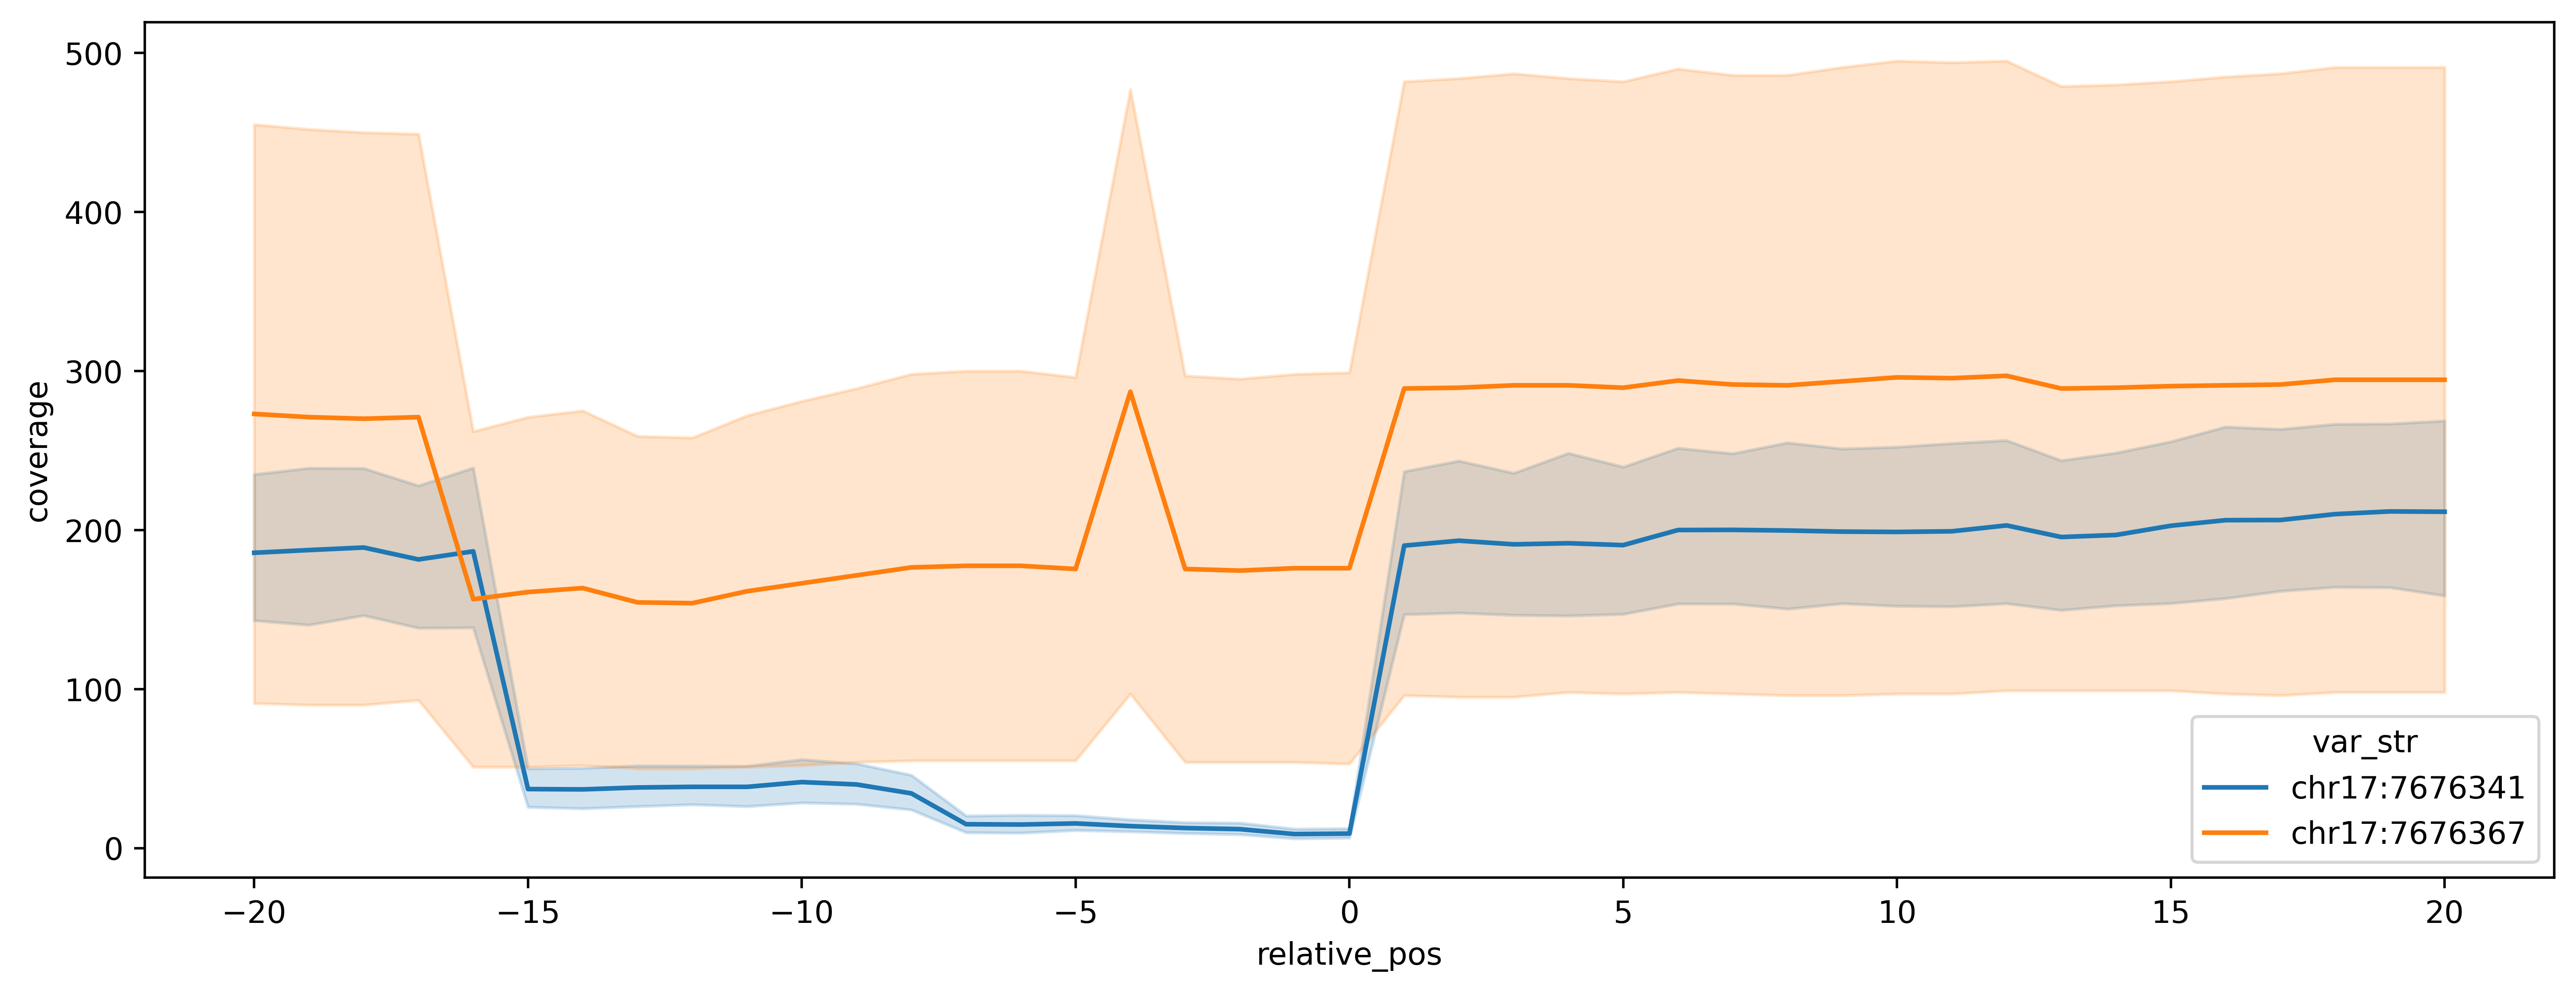

In [111]:
plt.figure(figsize=(14, 5))
# sns.lineplot(data=coverage_investigation[(coverage_investigation['SampleID']=='barcode10')], x='relative_pos', y='coverage', )
ax = sns.lineplot(data=coverage_investigation, x='relative_pos', y='coverage', hue='var_str', legend=True,)

# Figure 3e. VAF concordance between NGS and ONT

In [115]:
NGS_exclusive_variants          = set_NGS_variants.difference( set_ONT_variants_s )
NGS_exclusive_patho_variants    = set_NGS_patho_variants.difference( set_ONT_patho_variants_s )
print(f'Total variants exclusive to NGS: {len(NGS_exclusive_variants)}')
print(f'Patho variants exclusive to NGS: {len(NGS_exclusive_patho_variants)}')

NGS_variants_clinvar_exclusive = NGS_variants_clinvar[(NGS_variants_clinvar['Identifier_SampleID'].isin(NGS_exclusive_variants))].copy()
NGS_variants_clinvar_exclusive.reset_index(inplace=True, drop=True)

Total variants exclusive to NGS: 61
Patho variants exclusive to NGS: 6


In [ ]:
# list_DIR_ONT_BAM = glob.glob(f'/data01/node200data/18parkky/datasets/data/FGL/FASTQ/AML_TS_Run*sup')
# dict_barcode_to_PATH_BAM = dict()

# min_base_quality    = 0
# min_mapping_quality = 0 

# for DIR_ONT_BAM in list_DIR_ONT_BAM:
#     list_PATH_mm2_BAM = glob.glob(f'{DIR_ONT_BAM}/minimap2_out/*.bam')
#     for PATH_mm2_BAM in list_PATH_mm2_BAM:
#         barcode = os.path.basename(PATH_mm2_BAM.split('.')[0])
#         dict_barcode_to_PATH_BAM[barcode] = PATH_mm2_BAM

# dict_IdentifierSampleID_to_ONT_info = dict()
# for SampleID, edf in NGS_variants_clinvar_exclusive.groupby('SampleID'):
#     ONT_bamfile = pysam.AlignmentFile(dict_barcode_to_PATH_BAM[SampleID], 'rb')

#     for tup in edf.itertuples():
#         chrom = list(tup)[1]
#         allele_counts = get_allele_counts(ONT_bamfile, chrom, tup.POS, min_base_quality, min_mapping_quality)
#         if tup.ALT not in ['A', 'T', 'G', 'C'] or tup.REF not in ['A', 'T', 'G', 'C']:
#             ONT_ALT_allele_DP = 0 
#             ONT_ALT_allele_AF = 0 
#         else:
#             try:
#                 ONT_ALT_allele_DP = allele_counts[tup.ALT]
#                 ONT_ALT_allele_AF = allele_counts[tup.ALT] / sum(allele_counts.values())

#             except KeyError:
#                 ONT_ALT_allele_DP = 0 
#                 ONT_ALT_allele_AF = 0 

#         dict_IdentifierSampleID_to_ONT_info[tup.Identifier_SampleID] = (ONT_ALT_allele_AF, ONT_ALT_allele_DP)

# NGS_variants_clinvar_exclusive['ONT_AF'] = NGS_variants_clinvar_exclusive['Identifier_SampleID'].map(dict_IdentifierSampleID_to_ONT_info).str[0]
# NGS_variants_clinvar_exclusive['ONT_DP'] = NGS_variants_clinvar_exclusive['Identifier_SampleID'].map(dict_IdentifierSampleID_to_ONT_info).str[1]

# dict_IdentifierSampleID_to_ONT_info_2 = { tup.Identifier_SampleID : [tup.AF, tup.DP] for tup in ONT_variants_clinvar_s.itertuples() }
# NGS_variants_clinvar_intersection = NGS_variants_clinvar[~(NGS_variants_clinvar['Identifier_SampleID'].isin(NGS_exclusive_variants))].copy()
# NGS_variants_clinvar_intersection['ONT_AF'] = NGS_variants_clinvar_intersection['Identifier_SampleID'].map(dict_IdentifierSampleID_to_ONT_info_2).str[0]
# NGS_variants_clinvar_intersection['ONT_DP'] = NGS_variants_clinvar_intersection['Identifier_SampleID'].map(dict_IdentifierSampleID_to_ONT_info_2).str[1]

# NGS_variants_clinvar_intersection.to_csv(f'{DIR_data}/ngs_ont_concordance/intersecting_clinvar_patho_variants_NGS.tsv.gz', sep='\t', index=False, compression='gzip')


In [137]:
NGS_variants_clinvar_intersection = pd.read_csv(f'{DIR_data}/ngs_ont_concordance/intersecting_clinvar_patho_variants_NGS.tsv.gz', sep='\t',)

PearsonRResult(statistic=0.9174681083611473, pvalue=1.7692129914721418e-191)


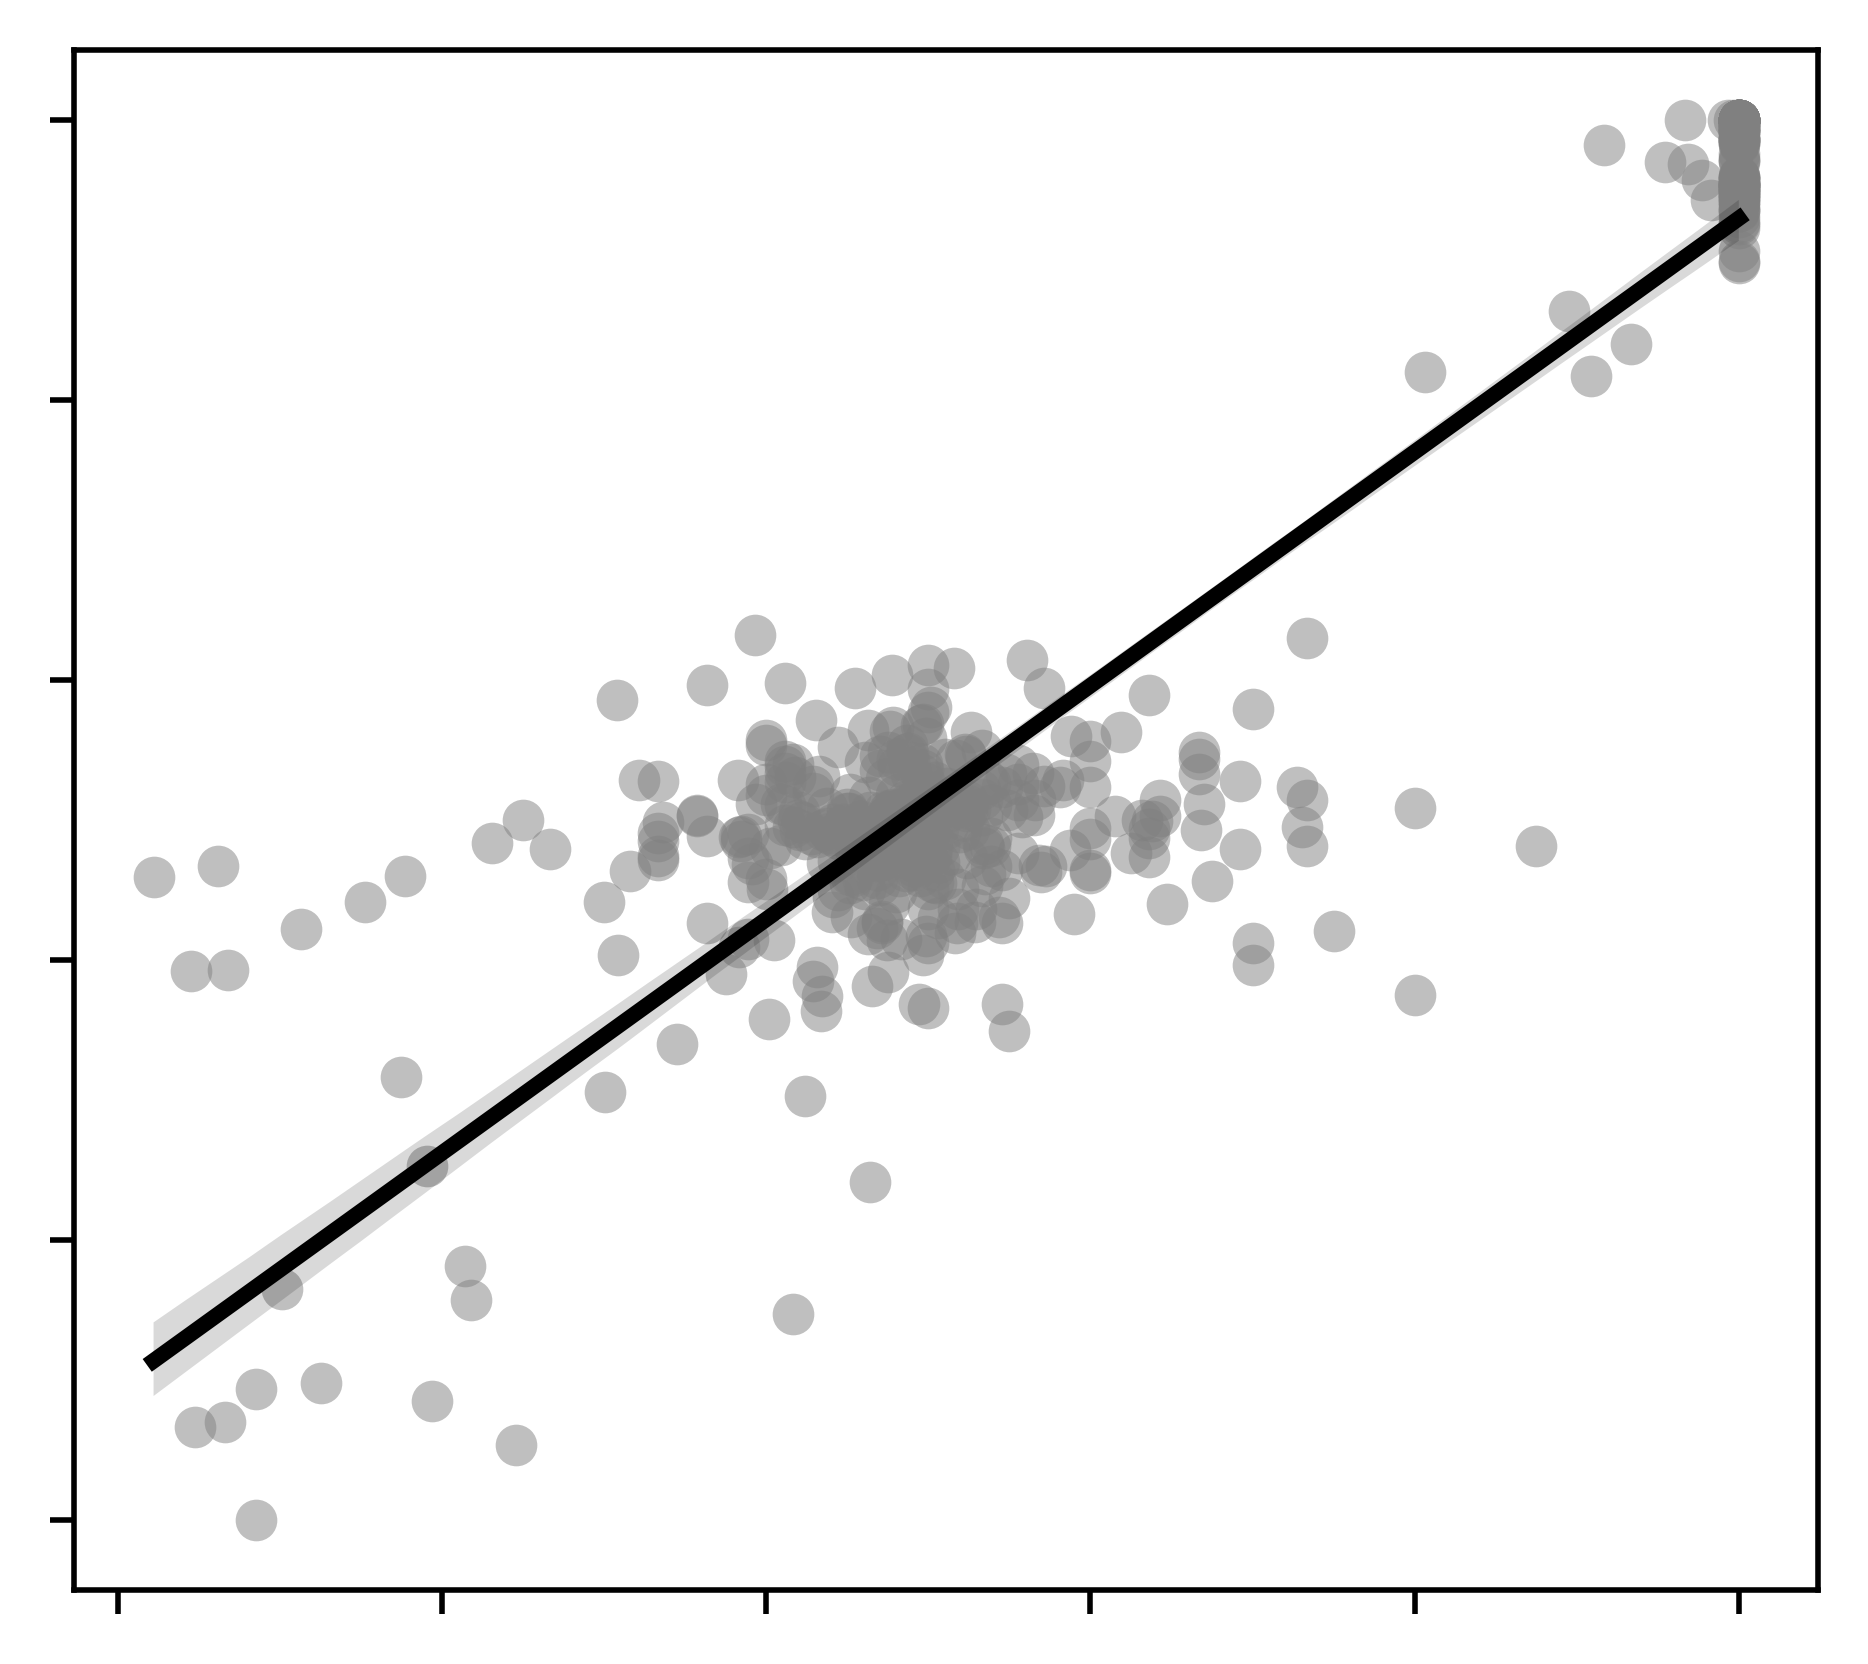

In [ ]:
# plt.figure(figsize=(4.5, 3.5), dpi=300)
plt.figure(figsize=(4.5, 4), dpi=500)
ax = sns.scatterplot(data=NGS_variants_clinvar_intersection, x='AF', y='ONT_AF', alpha=0.5, color='gray', linewidth=0, )
ax = sns.regplot(data=NGS_variants_clinvar_intersection, x='AF', y='ONT_AF', scatter=None, color='black', )
print(stats.pearsonr( NGS_variants_clinvar_intersection['AF'], NGS_variants_clinvar_intersection['ONT_AF'] ))
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticklabels([]);
ax.set_yticklabels([]);
plt.show()

# Figure 3f - Subsampling analysis

In [145]:
DIR_subsampling_analysis_results = f'{DIR_data}/subsampling_analysis'

subsample_total_variants = pd.read_csv(f'{DIR_subsampling_analysis_results}/all_variants.tsv', sep='\t')
subsample_patho_variants = pd.read_csv(f'{DIR_subsampling_analysis_results}/patho_variants.tsv', sep='\t')

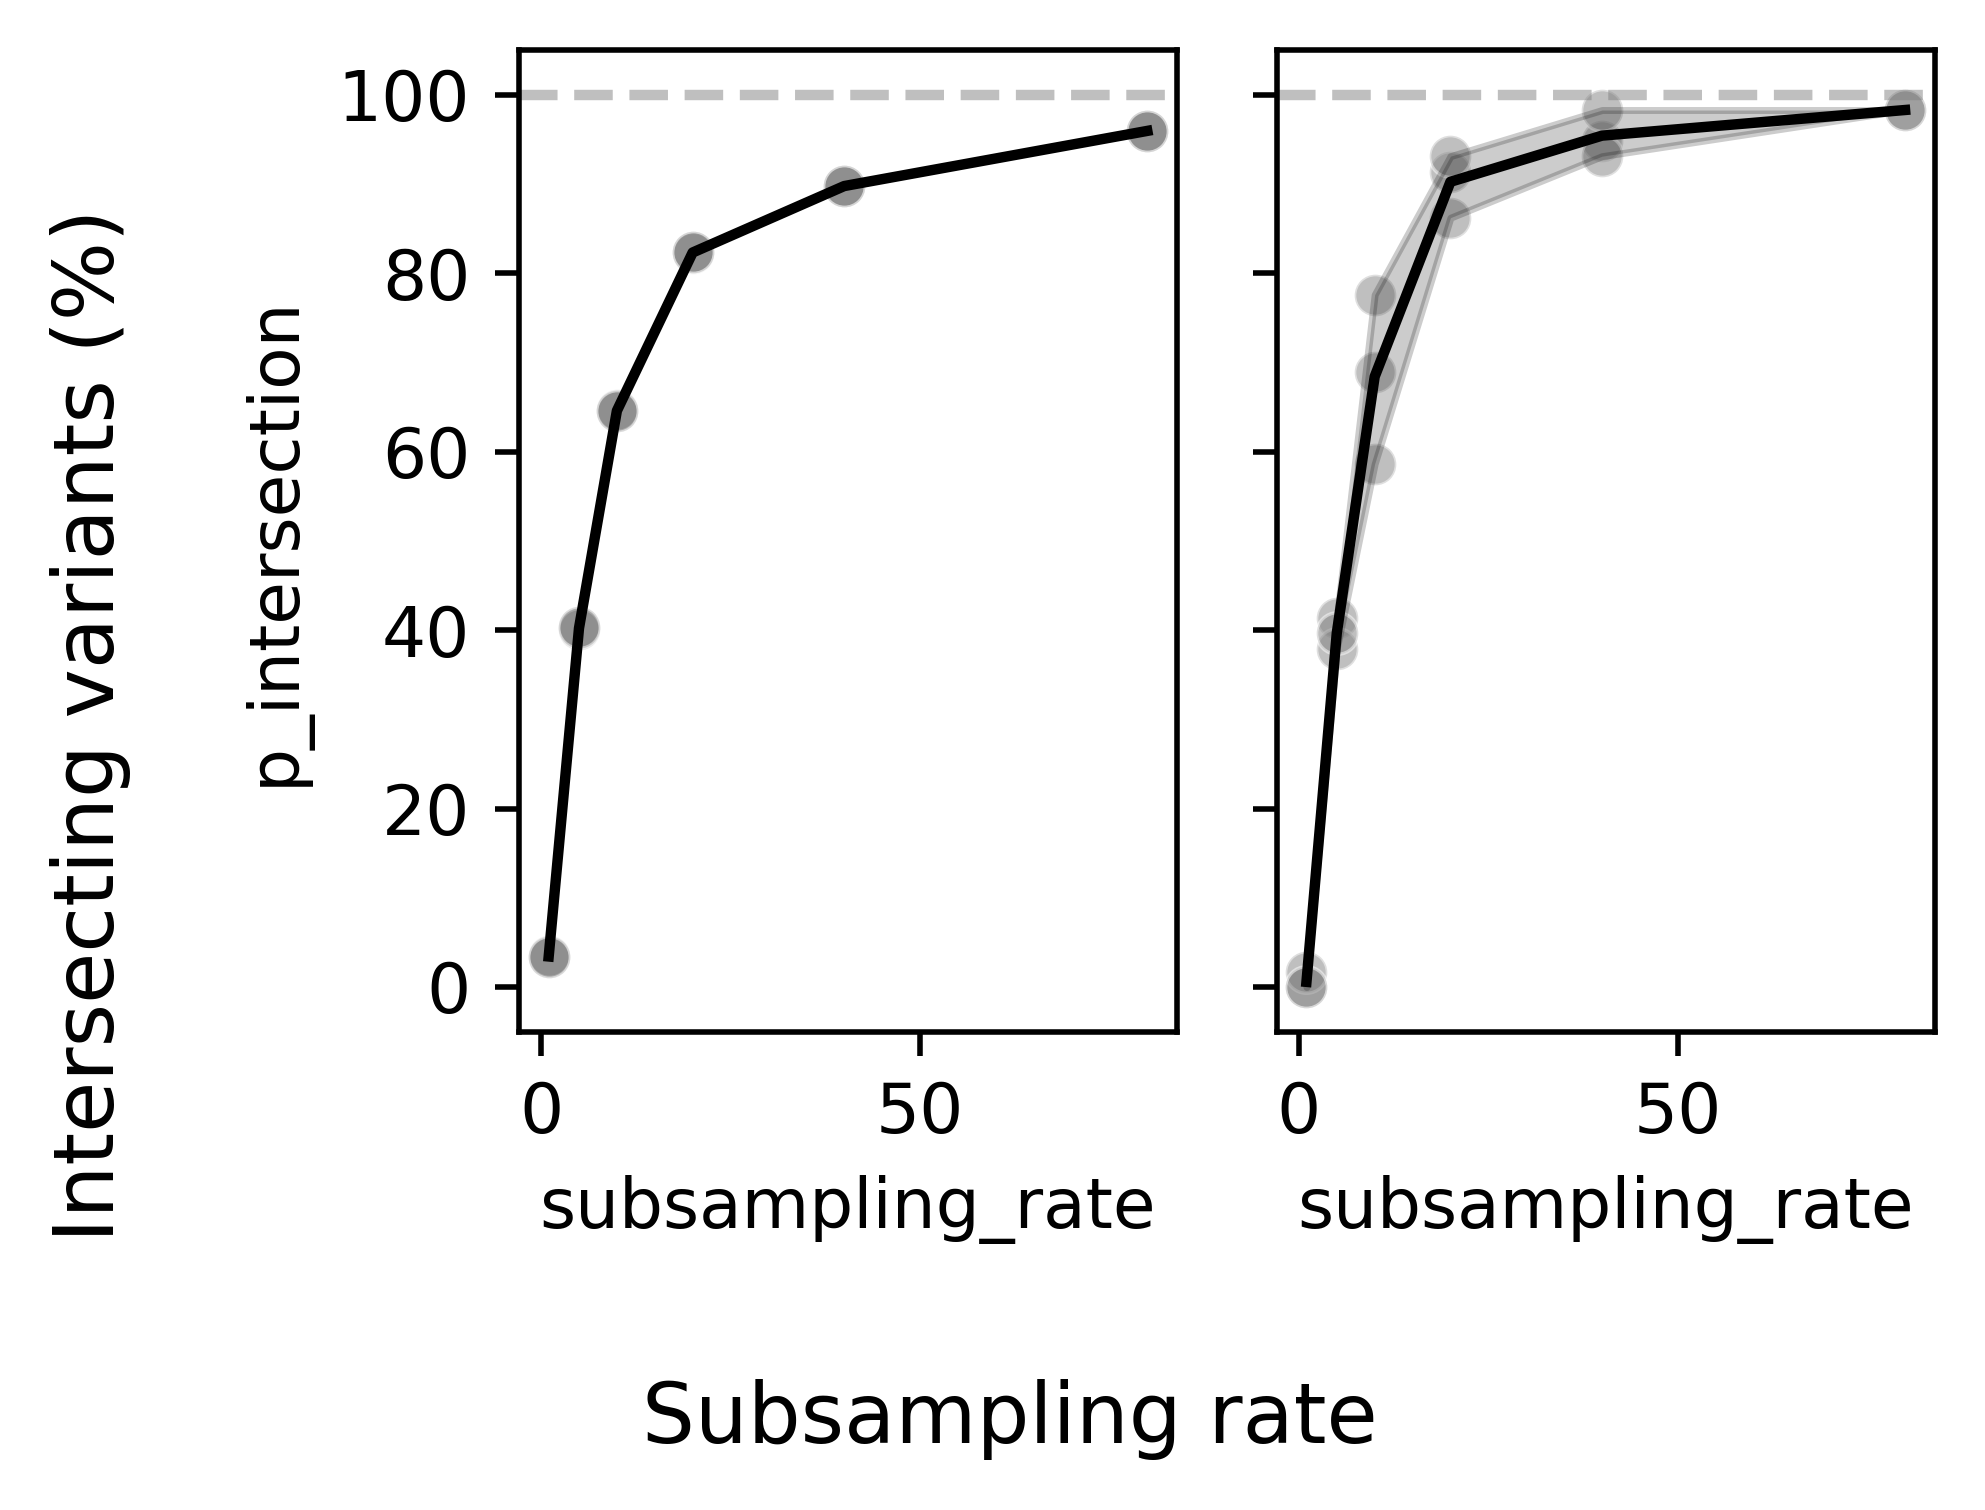

In [148]:
fig, axes = plt.subplots(1, 2, figsize=(4, 3), sharex=True, sharey=True, dpi=500)

seed_palette = { 'seed_42' : 'chocolate', 'seed_43' : 'olive', 'seed_44' : 'teal', }

sns.scatterplot(data=subsample_total_variants, x='subsampling_rate', y='p_intersection', ax=axes[0], color='gray', legend=None, alpha=0.5,)
sns.lineplot(data=subsample_total_variants, x='subsampling_rate', y='p_intersection', color='black', ax=axes[0], )
axes[0].axhline(100, ls='--', alpha=0.5, color='gray')
axes[0].set_ylim([-5, 105]);
# axes[0].set_xlabel('');
# axes[0].set_ylabel('');

sns.scatterplot(data=subsample_patho_variants, x='subsampling_rate', y='p_intersection', color='gray', ax=axes[1], legend=None, alpha=0.5,)
sns.lineplot(data=subsample_patho_variants, x='subsampling_rate', y='p_intersection', color='black', ax=axes[1], )
axes[1].axhline(100, ls='--', alpha=0.5, color='gray')
axes[1].set_ylim([-5, 105]);
# axes[1].set_xlabel('');
# axes[1].set_ylabel('');

# axes[0].set_xticks([1, 10, 20, 40, 80]);
# axes[0].set_xticklabels([]);
# axes[0].set_yticklabels([]);
fig.supxlabel('Subsampling rate');
fig.supylabel('Intersecting variants (%)');
fig.tight_layout();